<a href="https://colab.research.google.com/github/MarcoLuw/semal27-stereoqueereval/blob/main/experiments/StereoQueerEval_task1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_en = pd.read_csv("StereoQueerEval_EN_training.tsv", sep="\t")
df_it = pd.read_csv("StereoQueerEval_IT_training.tsv", sep="\t")
df_nl = pd.read_csv("StereoQueerEval_NL_training.tsv", sep="\t")
df_fa = pd.read_csv("StereoQueerEval_FA_training.tsv", sep="\t") # For testing purpose only

In [ ]:
df_en.head(n=10)

In [ ]:
df_it.head(n=10)

In [ ]:
df_nl.head()

In [ ]:
df_fa.head()

In [7]:
print(df_en.shape)
print(df_it.shape)
print(df_nl.shape)
print(df_fa.shape)

(2989, 7)
(2400, 7)
(2238, 7)
(100, 7)


# 1. Preprocessing

## Checking missing value

In [8]:
# Check columns which have missing values
print(df_en.columns[df_en.isnull().any()])
print(df_it.columns[df_it.isnull().any()])
print(df_nl.columns[df_nl.isnull().any()])
print(df_fa.columns[df_fa.isnull().any()])

Index([], dtype='object')
Index([], dtype='object')
Index([], dtype='object')
Index([], dtype='object')


No missing value found

## Handle special cases
In dataset columns, data are containing:
- Punctuation
- Emojis
- Special symbols/characters: e.g., ►, ♥
- Uppercase placeholders: [CHANNEL], [URL]

### 1st. Check how many different uppercase substitutions in the dataset

In [9]:
import re

pattern = re.compile(r'\[[A-Z0-9_]+\]')
cols = ["yt_title", "yt_description",	"yt_comment"]
dataset_lst = [df_en, df_it, df_nl]
upcs_dict = dict()
for i in range(len(dataset_lst)):
  upcs_set = set()
  for col in cols:
    upcs_set.update(dataset_lst[i][col].dropna().astype(str).str.findall(pattern).explode().dropna())
  upcs_dict[i] = upcs_set

print(upcs_dict)

{0: {'[CHANNEL]', '[EMAIL]', '[URL]', '[USER]'}, 1: {'[CHANNEL]', '[EMAIL]', '[URL]', '[USER]'}, 2: {'[CHANNEL]', '[EMAIL]', '[URL]', '[USER]'}}


**Findings**

Each column contains: **[EMAIL], [USER], [CHANNEL], [URL]**

Two options:
- Keep these placeholders as-is
- Remove all placeholders before training

### 2nd. Check the emojis existence in english dataset

In [10]:
!pip install emoji==2.16.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 10.6 MB/s  0:00:00


In [11]:
import emoji

# Boolean mask: True where the comment has at least one emoji
mask = df_en['yt_comment'].fillna('').astype(str).map(lambda s: emoji.emoji_count(s) > 0)

# Comment filter
emoji_comments = df_en[mask]

print(f"{len(emoji_comments)} comments contain emojis")

# Get at least 10 comments
sample = emoji_comments.tail(10)
for _, row in sample.iterrows():
  print(f"Comment: {row["yt_comment"]}")
  print(f"Hate speech: {row["hate_speech"]}", "\n")

357 comments contain emojis
Comment: who really cares what adults want to do with their bodies cool the dad didn't leave for those decisions. Nobody in their right mind wants "gender affirming care" for children there's a line that has to be drawn. but if an adult wants to take the cleaver to his wee wee power to that individual freedom is a double edge sword for sure but gotta love it. 😂
Hate speech: yes_implicit 

Comment: You can’t the gender biologically.😂
Hate speech: yes_implicit 

Comment: I hear you.😊😊
Hate speech: no 

Comment: Dem a get to bright so mi bun battyman and sodamite😂😂😂
Hate speech: yes_implicit 

Comment: Let's teach our children to spread love, peace, and cooperation, not hatred, enmity, and war!
🇮🇷🤝🏻🇺🇸
Hate speech: no 

Comment: [CHANNEL] a massive company built on nothing but gay guys who put nail clippers whistles Walmart empty bags key chains banana peelings & specially 🍆 up their ButtHoles anyways 🤷‍♂️
Hate speech: yes_explicit 

Comment: THANK YOU SARAH. ON

**Findings**

Nowadays, with transformer-based models like BERT, we do not need to remove emoijis or punctuation in the texts because they help keep the sentiment or emotion signal.

For example:
- In reality: "That's great 😒" is completely different from "That's great 🥰"
- In this dataset:
  - Comment: *What's next, a blind, deaf, mentally handicap, quadriplegic Superman? 🤦‍♂️"*
  - Hate speech: *yes_implicit* (🤦‍♂️ has changed the signals)

Therefore, it's important to keep the emotions and punctuation in youtube comments

### 3rd. Check special symbols/characters

## Check and remove duplications


In [12]:
for df in dataset_lst:
  before = len(df)
  df = df.drop_duplicates(subset=["yt_title", "yt_description", "yt_comment"], keep="first")
  after = len(df)
  print(f"Removed {before - after} duplicate rows ({before} -> {after})")

Removed 0 duplicate rows (2989 -> 2989)
Removed 0 duplicate rows (2400 -> 2400)
Removed 0 duplicate rows (2238 -> 2238)


No duplication in original training datasets

## Check text length

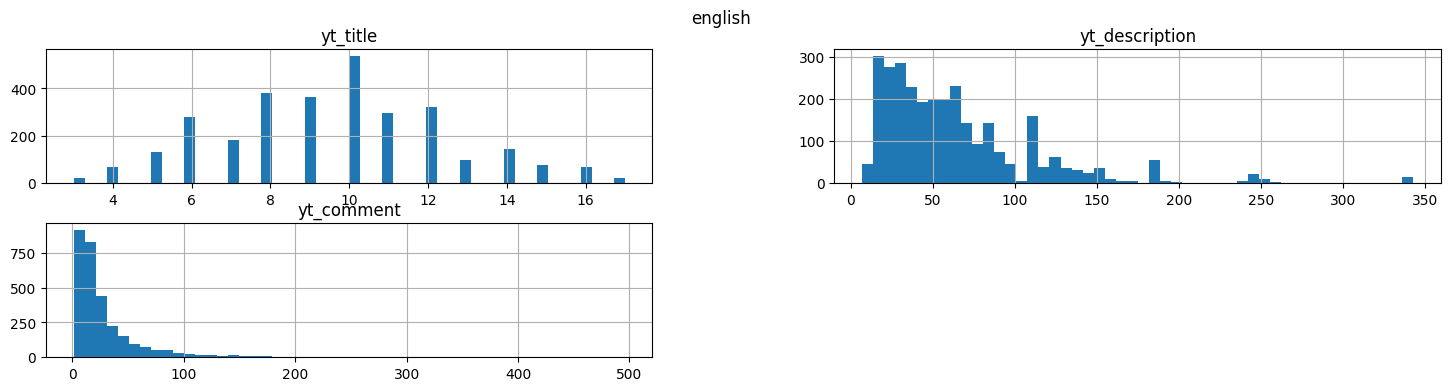

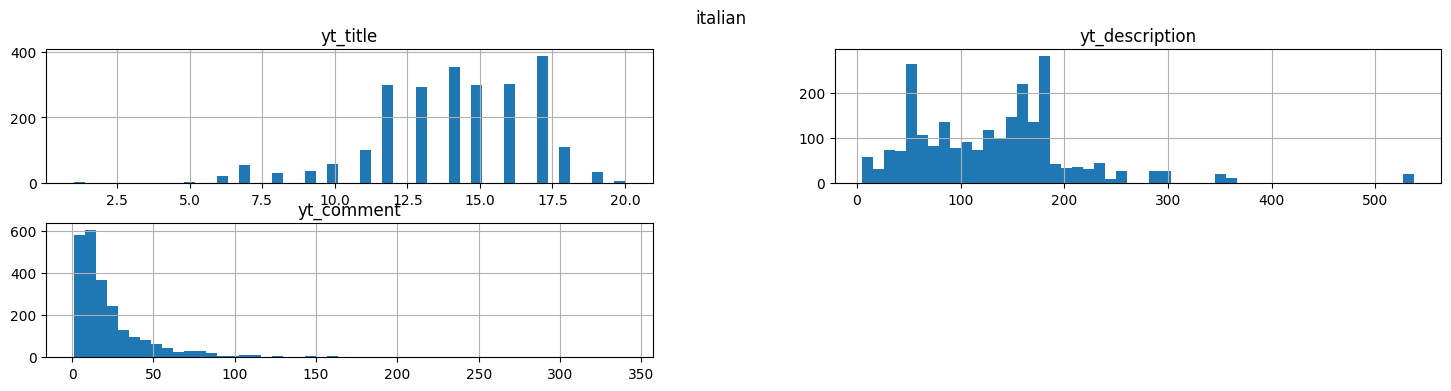

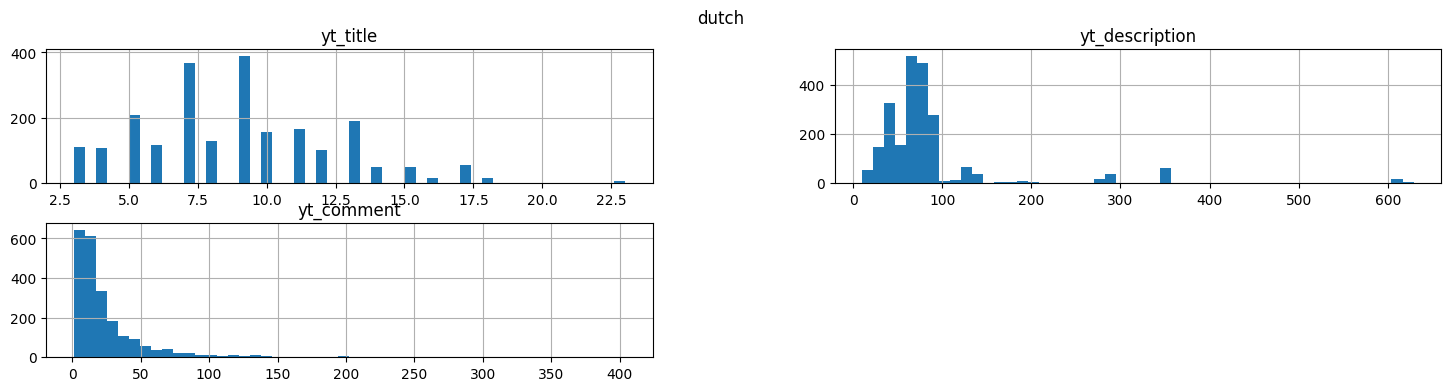

In [13]:
cols = ["yt_title", "yt_description", "yt_comment"]
lang_names = ["english", "italian", "dutch", "persian"]

for df in dataset_lst:
  for c in cols:
    df[f"{c}_wc"] = df[c].fillna("").astype(str).str.split().str.len()

for df, name in zip(dataset_lst, lang_names):
    wc = df[cols].apply(lambda col: col.fillna("").astype(str).str.split().str.len())
    wc.hist(bins=50, figsize=(18, 4))
    plt.suptitle(name)
    plt.show()

In [ ]:
dataset_lst[0].head() # english dataset after adding word count for each text-format column

### Check word count in english comment

In [15]:
d = dataset_lst[0]  # english
wc = d["yt_comment"].fillna("").astype(str).str.split().str.len()

print("lowest word count:", wc.min())
print("highest word count:", wc.max())

print("=== shortest comments ===")
print(d.loc[wc.sort_values().index[:5], "yt_comment"].tolist())

print("\n=== longest comments ===")
print(d.loc[wc.sort_values().index[-1:], "yt_comment"].tolist())

lowest word count: 1
highest word count: 496
=== shortest comments ===
['She😂😂😂😂', '#perfection', 'Boycott!!', 'Womanface', 'hypocrite']

=== longest comments ===
["The inclusion of male athletes in girls' and women's sports, an issue that fundamentally challenges the principles of fairness, safety, and equality in athletic participation. Governing bodies such as the National Collegiate Athletic Association (NCAA), the National Federation of State High School Activities Associations (NFHS), and the respective sport governing organizations involved in Olympic competition hold fiduciary responsibilities to draft rules that ensure equitable competition, prioritize athlete safety, and account for the maturation of athletes at all levels. Allowing male participation in girls' and women's sports is inconsistent with these responsibilities.\nThe cornerstone of any sport's rules is to foster fair play. It is a widely acknowledged biological fact that male bodies are generally built stronger an

### Box plot of english comment's word count

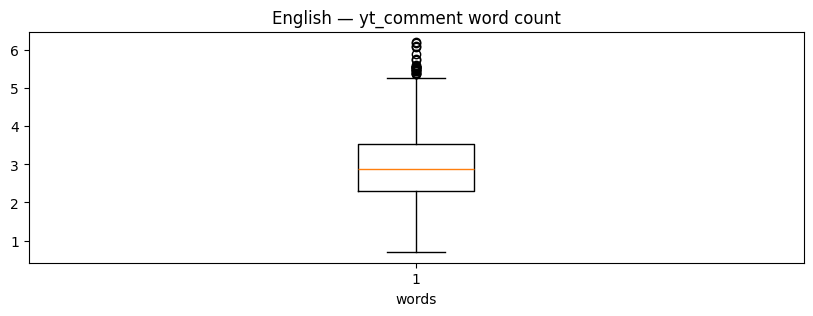

In [16]:
d = dataset_lst[0]  # english
wc = d["yt_comment"].fillna("").astype(str).str.split().str.len()

plt.figure(figsize=(10, 3))
plt.boxplot(np.log1p(wc))
plt.title("English — yt_comment word count")
plt.xlabel("words")
plt.show()

In [17]:
wc.describe()

,yt_comment
count,2989.000000
mean,29.195049
std,38.659436
min,1.000000
25%,9.000000
50%,17.000000
75%,33.000000
max,496.000000


In [18]:
q1, q3 = wc.quantile(0.25), wc.quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

outliers = wc[wc > upper]

print(f"whisker (upper bound): {upper:.1f} words")
print(f"number of outliers: {len(outliers)}  ({len(outliers)/len(wc)*100:.1f}% of comments)")
print(f"outlier min: {outliers.min()} words")
print(f"outlier max: {outliers.max()} words")

whisker (upper bound): 69.0 words
number of outliers: 282  (9.4% of comments)
outlier min: 70 words
outlier max: 496 words


Since 9.4% comments have more than 70 words, we can consider to set the max data length processed by the pre-trained LLM later.

For ML baseline, it is unnecessary to do it. Just keep it in mind!

## Check data imbalance

As the majority class may have a greater influence on the learning process, causing the model to favor that class.

- Biased Predictions: models focuses primarily on patterns from the majority class, while neglecting the specifics of the minority class
- Misleading metrics: models have tendency to have high overall accuracy but meaningless in reality (missing all rare fraud cases)

Example:
- In banking use-case, 99% of transactions are legitimate while only 1% are fraudulent => model could achieve upto 99% accuracy by classifying every transaction as legitimate, but this would be meaningless in practice

In [19]:
label_col = "stereotype"
for d, name in zip(dataset_lst, lang_names):
    print(name, d[label_col].unique())

english ['yes' 'no']
italian ['no' 'yes']
dutch ['no' 'yes']


In [20]:
lang_names = ["english", "italian", "dutch", "persian"]

for d, name in zip(dataset_lst, lang_names):
    counts = d[label_col].value_counts()
    pct = d[label_col].value_counts(normalize=True) * 100
    print(f"=== {name} (n={len(d)}) ===")
    for cls in counts.index:
        print(f"  {str(cls):5s} {counts[cls]:6d}  ({pct[cls]:5.1f}%)")
    print(f"  imbalance ratio (max/min): {counts.max() / counts.min():.2f}\n")

=== english (n=2989) ===
  no      1663  ( 55.6%)
  yes     1326  ( 44.4%)
  imbalance ratio (max/min): 1.25

=== italian (n=2400) ===
  no      1752  ( 73.0%)
  yes      648  ( 27.0%)
  imbalance ratio (max/min): 2.70

=== dutch (n=2238) ===
  no      1370  ( 61.2%)
  yes      868  ( 38.8%)
  imbalance ratio (max/min): 1.58



Current dataset is quite balanced except the italian, though it's good to proceed with the baseline.

We'll take this point into consideration later.

## Start preprocessing for baseline

Remove punctuation, symbols, emojis

In [21]:
import re
import pandas as pd
import regex  # better Unicode property support than built-in re

REMOVE_EMOJIS      = True
KEEP_PLACEHOLDERS  = True    # keep [URL], [CHANNEL], [EMAIL], [USER] intact
KEEP_INTRAWORD     = True    # keep ' and - inside words (don't, anti-fascista)

PLACEHOLDER_RE = re.compile(r"\[(?:URL|CHANNEL|EMAIL|USER)\]")
_PLACEHOLDER_SENTINEL = "\uE000{}\uE001"  # private-use chars, won't appear in text

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""

    # 1. Protect placeholder tokens so bracket-stripping won't touch them
    # Example:
    ## stash = ["[EMAIL]"] -> returns "\uE0000\uE001"
    ## stash = ["[EMAIL]", "[URL]"] -> returns "\uE0001\uE001"
    stash = []
    if KEEP_PLACEHOLDERS:
        def _stash(m):
            stash.append(m.group(0))
            return _PLACEHOLDER_SENTINEL.format(len(stash) - 1)
        text = PLACEHOLDER_RE.sub(_stash, text)

    # 2. Remove emojis (covers ZWJ sequences, flags, skin tones)
    if REMOVE_EMOJIS:
        text = emoji.replace_emoji(text, replace="")
        # To keep them as text instead, use:
        # text = emoji.demojize(text, delimiters=(" ", " "))

    # 3. Keep letters (ANY script: Latin, Persian, …), marks, numbers, whitespace.
    #    \p{L}=letter, \p{M}=combining marks (needed for Persian/accents),
    #    \p{N}=number. Everything else (symbols/punctuation) is dropped.
    if KEEP_INTRAWORD:
        # allow ' and - only when between two word chars
        text = regex.sub(r"(?<=[\p{L}\p{N}])['-](?=[\p{L}\p{N}])", "\uE002", text)
    text = regex.sub(r"[^\p{L}\p{M}\p{N}\s\uE000-\uE002]", " ", text)
    text = text.replace("\uE002", "'")  # restore protected intra-word marks

    # 4. Restore placeholders
    if KEEP_PLACEHOLDERS:
        for i, tok in enumerate(stash):
            text = text.replace(_PLACEHOLDER_SENTINEL.format(i), tok)

    # 5. Collapse whitespace
    return re.sub(r"\s+", " ", text).strip()


# ---- apply across all dataframes and columns ----------------
for df in dataset_lst:
    for col in cols:
        df[col] = df[col].apply(clean_text)

Verify

In [ ]:
df_en.head()

In [23]:
# Check emojis
for df, name in zip(dataset_lst, lang_names):
  # Boolean mask: True where the comment has at least one emoji
  mask = df['yt_comment'].fillna('').astype(str).map(lambda s: emoji.emoji_count(s) > 0)
  # Comment filter
  emoji_comments = df[mask]
  print(f"{name} dataset {len(emoji_comments)} comments contain emojis")

english dataset 0 comments contain emojis
italian dataset 0 comments contain emojis
dutch dataset 0 comments contain emojis


# Feature Engineering

## Feature Engineering for Baseline model

Baseline model: Logistic Regression

Feature extraction: TF-IDF

In [24]:
dataset_lst = [df_en, df_it, df_nl, df_fa]
cols = ["yt_title", "yt_description", "yt_comment"]

df_all = pd.concat(dataset_lst, ignore_index=True)
for c in cols:
    df_all[c] = df_all[c].fillna("")   # TF-IDF needs strings, not NaN

In [25]:
df_all.shape

(7727, 10)

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

# 1. Pool the 4 cleaned dataframes
dataset_lst = [df_en, df_it, df_nl]
cols = ["yt_title", "yt_description", "yt_comment"]

## We will split dataset of each language first before concatenating them to ensure the ratio of classes per each dataset
train_parts, test_parts = [], []
for df in dataset_lst:
  df_temp = df.copy()
  for c in cols:
    df_temp[c] = df_temp[c].fillna("")   # TF-IDF needs strings, not NaN
  y_lang = (df_temp["stereotype"].str.lower() == "yes").astype(int)

  train, test = train_test_split(df_temp, test_size=0.2, random_state=42, stratify=y_lang)
  train_parts.append(train)
  test_parts.append(test)

train_df = pd.concat(train_parts, ignore_index=True)
test_df  = pd.concat(test_parts,  ignore_index=True)
test_df = pd.concat([test_df, df_fa], ignore_index=True) # append Persian dataset to test set

# 2. Split FIRST
# "stratify" = preserve the same proportion of each class when splitting
X_train = train_df[cols]
X_test = test_df[cols]
y_train = (train_df["stereotype"].str.lower() == "yes").astype(int)   # Boolean -> int
y_test = (test_df["stereotype"].str.lower() == "yes").astype(int)

# 3. One TF-IDF per field, bundled
# Splits text into tokens, preserving supported placeholders
  # => text: "Hello [URL] user123!"  ->  ["Hello", "[URL]", "user123"]
# Generates unigrams and bigrams
  # => "I love cat" = "I, love, cat" + "I love, love cat"
# Excludes features appearing in fewer than 2 documents.
# Excludes features appearing in more than 90% of documents.
# Calculates TF-IDF weights, using sublinear term frequency.
  # => count(t,d) -> 1 + log(count(t,d))
# Converts text to lowercase.
def make_tfidf():
    return TfidfVectorizer(
        token_pattern=r"\[[a-zA-Z]+\]|\w+",   # keep [URL]-style placeholders whole
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.9,
        sublinear_tf=True,
        lowercase=True,
    )

# ColumnTransformer(...) -> Applies different transformations to selected columns of a DataFrame.
# "title"	-> assign name to this transformation.
# make_tfidf() -> create a new TF-IDF vectorizer for this column.
# "yt_title" -> The column that this vectorizer processes.
# remainder="drop" -> Discards all columns not explicitly selected.
vectorizer = ColumnTransformer(
    transformers=[
        ("title",   make_tfidf(), "yt_title"),
        ("desc",    make_tfidf(), "yt_description"),
        ("comment", make_tfidf(), "yt_comment"),
    ],
    remainder="drop",
)

X_train_vec = vectorizer.fit_transform(X_train)   # FIT on train only
X_test_vec = vectorizer.transform(X_test)        # transform test

print("train matrix:", X_train_vec.shape, " test matrix:", X_test_vec.shape)

train matrix: (6101, 68291)  test matrix: (1626, 68291)


In [27]:
print(X_train.head(n=1))
print(X_train.shape)

                                            yt_title  \
0  LGBTQ activist Edwin Chiloba found dead in Ken...   

                                      yt_description  \
0  Police in Kenya are investigating the death of...   

                           yt_comment  
0  LGBT life has the least importance  
(6101, 3)


In [28]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6101 entries, 0 to 6100
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   yt_title        6101 non-null   object
 1   yt_description  6101 non-null   object
 2   yt_comment      6101 non-null   object
dtypes: object(3)
memory usage: 143.1+ KB


In [29]:
print(y_train.head(n=1))
print(y_train.shape)

0    1
Name: stereotype, dtype: int64
(6101,)


In [30]:
y_train.info()

<class 'pandas.core.series.Series'>
RangeIndex: 6101 entries, 0 to 6100
Series name: stereotype
Non-Null Count  Dtype
--------------  -----
6101 non-null   int64
dtypes: int64(1)
memory usage: 47.8 KB


## Verify

Check 1: the column count is exactly the three vocabularies summed.

Check 2: train and test have identical column counts (vocab fit on train only, no leak), and no rows were dropped.

Check 3: feature names carry field prefixes (title__, desc__, comment__), your [URL]-style tokens survived, and density is <1% (expected — almost every cell is 0).

In [31]:
# CHECK 1: sum of the 3 vocab sizes = X_train_vec vocab = X_test_vec vocab
sizes = {}
for name, trans, col in vectorizer.transformers_:
    sizes[name] = len(trans.vocabulary_)
print(sizes, "→ sum =", sum(sizes.values()))
print("matrix cols =", X_train_vec.shape[1])
assert sum(sizes.values()) == X_train_vec.shape[1]   # passes = proven

{'title': 6571, 'desc': 36948, 'comment': 24772} → sum = 68291
matrix cols = 68291


In [32]:
# CHECK 2: rows unchanged, test has SAME cols as train
print("train:", X_train_vec.shape, " test:", X_test_vec.shape)
assert X_train_vec.shape[1] == X_test_vec.shape[1]     # same vocab = leak-safe
assert X_train_vec.shape[0] == len(y_train)             # rows = docs, not lost

train: (6101, 68291)  test: (1626, 68291)


In [33]:
# CHECK 3: peek at real feature names + sparsity
names = vectorizer.get_feature_names_out()
print(len(names), "features")          # == 70,524
print(names[:5], "...", names[-5:])    # see title__ / comment__ prefixes
print("placeholder kept?:", [n for n in names if "[url]" in n][:3])

density = X_train_vec.nnz / (X_train_vec.shape[0] * X_train_vec.shape[1])
print(f"density = {density:.4%}")      # expect <1% → normal sparse TF-IDF

68291 features
['title__000' 'title__000 protests' 'title__08' 'title__100'
 'title__100 cose'] ... ['comment__é un' 'comment__één' 'comment__één woord' 'comment__óók'
 'comment__überhaupt']
placeholder kept?: ['desc__[channel] [url]', 'desc__[url]', 'desc__[url] 30']
density = 0.3057%


In [34]:
names = vectorizer.get_feature_names_out()
print([n for n in names if "url]" in n.lower()][:5])
print([n for n in names if "channel]" in n.lower()][:5])
print([n for n in names if "email]" in n.lower()][:5])
print([n for n in names if "user]" in n.lower()][:5])

['desc__[channel] [url]', 'desc__[url]', 'desc__[url] 30', 'desc__[url] [channel]', 'desc__[url] [url]']
['title__1950s [channel]', 'title__[channel]', 'title__[channel] [channel]', 'title__[channel] anchor', 'title__[channel] archives']
['desc__[email]', 'desc__[email] abonneer', 'desc__[email] en', 'desc__[email] eventuali', 'desc__[email] in']
['desc__[user]', 'desc__[user] credit', 'desc__band [user]', 'comment__[user]']


What does "density" mean?

Total cells = 6,181 x 70,524 = 435 million cells. <br/>
Of those, only ~0.3% have a value. The other 99.7% are zero.

**Explanation:**
- The whole dataset has 70,524 vocabularies but a single comment would only use 10-30 words
- So that one row can light up 10-30 columns (not 0) while other columns are words that the comment didn't use -> (= 0)

**Evaluation:**
- 0.3% density is expected => Short documents + huge vocabulary = sparse
- If density is high (> 50%) => Every comment uses half of all known words, **unrealistic**


# Model Training

Training baseline model: logistic regression




## Fitting model

### Single try

Fitting model with single set of hyperparameters:
- **penalty** = regularization constraint: l2
- **C** = regularization magnitude: 1
- **class_weight** = balance class at algorithm-level: balanced
- **solver** = optimization algorithm: lbfgs

In [35]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(
    max_iter=1000,              # TF-IDF needs more iterations to converge
    class_weight="balanced",    # handle class imbalance at algorithm-level
    random_state=42,
)

classifier.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

### Fitting model with Grid Search CV

In [36]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {   # L2 branch
        "penalty": ["l2"],
        "C": [0.01, 0.1, 1, 10],
        "class_weight": [None, "balanced"],
        "solver": ["liblinear"],
    },
    {   # L1 branch (feature selection)
        "penalty": ["l1"],
        "C": [0.01, 0.1, 1, 10],
        "class_weight": [None, "balanced"],
        "solver": ["liblinear"],
    },
]

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid,
    scoring="f1_macro",   # tune for the metric you report, not accuracy
    cv=5,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train_vec, y_train)

print("best params:", grid.best_params_)
print("best CV macro-F1:", round(grid.best_score_, 4))

# Evaluate the winner on the held-out test set
best_classifier = grid.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits
best params: {'C': 10, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
best CV macro-F1: 0.6371


## Evaluation

### Evaluate the single baseline

In [37]:
from sklearn.metrics import classification_report, f1_score, confusion_matrix

y_pred = classifier.predict(X_test_vec)
f1 = f1_score(y_test, y_pred, average="macro")
cm = confusion_matrix(y_test, y_pred)
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))
print("macro-F1:", f1)
print("confusion matrix:\n", cm)

              precision    recall  f1-score   support

          no       0.77      0.69      0.73      1034
         yes       0.54      0.64      0.58       592

    accuracy                           0.67      1626
   macro avg       0.65      0.66      0.65      1626
weighted avg       0.68      0.67      0.67      1626

macro-F1: 0.6545507676754913
confusion matrix:
 [[711 323]
 [215 377]]


In [38]:
classifier.classes_

array([0, 1])

Confusion matrix display

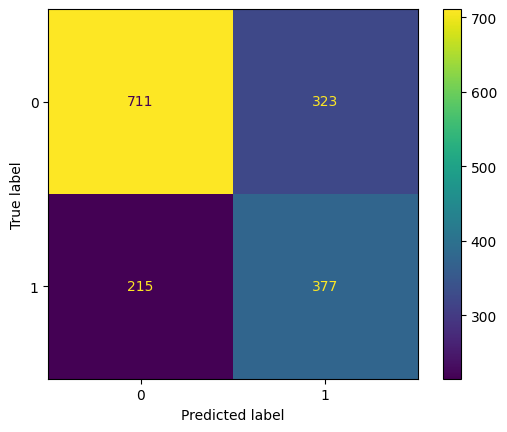

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classifier.classes_)
disp.plot()
plt.show()

Confusion matrix
[[711 323]
 [215 377]]


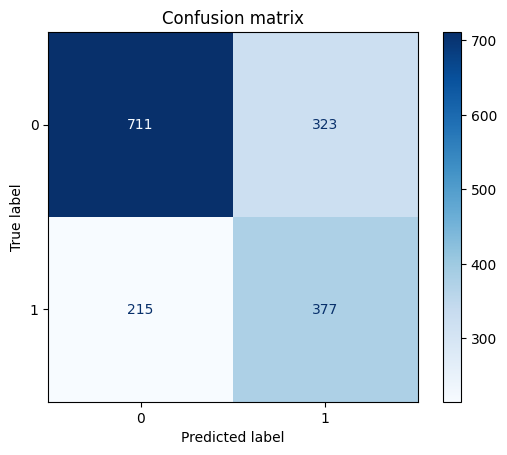

In [40]:
np.set_printoptions(precision=2)

# It is recommended to use "ConfusionMatrixDisplay.from_estimator" rather than "ConfusionMatrixDisplay" itself
title = "Confusion matrix"
disp = ConfusionMatrixDisplay.from_estimator(
    classifier,
    X_test_vec,
    y_test,
    display_labels=classifier.classes_,
    cmap=plt.cm.Blues
)
disp.ax_.set_title(title)

print(title)
print(disp.confusion_matrix)

plt.show()

### Evaluate the best estimator from GridCV

In [41]:
y_pred = best_classifier.predict(X_test_vec)
f1 = f1_score(y_test, y_pred, average="macro")
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))
print("macro-F1:", f1)

              precision    recall  f1-score   support

          no       0.76      0.73      0.74      1034
         yes       0.56      0.59      0.57       592

    accuracy                           0.68      1626
   macro avg       0.66      0.66      0.66      1626
weighted avg       0.68      0.68      0.68      1626

macro-F1: 0.6592523202219176


Confusion matrix
[[758 276]
 [243 349]]


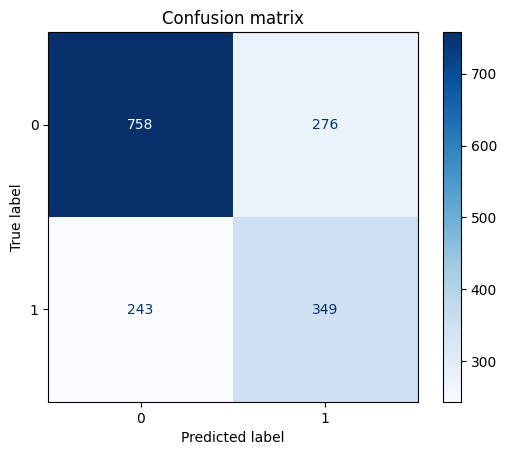

In [42]:
# Plot non-normalized confusion matrix
title = "Confusion matrix"
disp = ConfusionMatrixDisplay.from_estimator(
    best_classifier,
    X_test_vec,
    y_test,
    display_labels=best_classifier.classes_,
    cmap=plt.cm.Blues
)
disp.ax_.set_title(title)

print(title)
print(disp.confusion_matrix)

plt.show()

## Some analyses on Model explanation

In [43]:
# Checking wrong classification
wrong_pred = test_df[y_test.values != y_pred]

In [44]:
wrong_pred.info()

<class 'pandas.core.frame.DataFrame'>
Index: 519 entries, 3 to 1624
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   StereoQueerEval_id  519 non-null    object 
 1   yt_title            519 non-null    object 
 2   yt_description      519 non-null    object 
 3   yt_comment          519 non-null    object 
 4   stereotype          519 non-null    object 
 5   hate_speech         519 non-null    object 
 6   target              519 non-null    object 
 7   yt_title_wc         496 non-null    float64
 8   yt_description_wc   496 non-null    float64
 9   yt_comment_wc       496 non-null    float64
dtypes: float64(3), object(7)
memory usage: 44.6+ KB


In [45]:
wrong_pred[cols + ["stereotype"]].head()

,yt_title,yt_description,yt_comment,stereotype
3,Lesbian couple challenge NHS over gay tax fert...,A lesbian couple are challenging a discriminat...,The sense of entitlement is strong in these two,yes
9,Supreme Court conservatives signal support for...,The Supreme Court of the United States heard m...,Or you could just leave it up to the sports go...,no
11,Fencer kneels in protest against opponent she ...,USA Fencing disqualified fencer Stephanie Turn...,Good for you Stephanie what a bunch of garbage,yes
14,Pete Buttigieg responds to Mike Johnson's view...,Transportation Secretary Pete Buttigieg D resp...,I don't agree with the concept of same sex mar...,no
16,Ben Carson Being gay is a choice look at inmates,Potential GOP presidential contender Dr Ben Ca...,Homosexuality is learned,yes


In [46]:
# See coefficients
print(type(classifier.coef_))
print(classifier.coef_.shape)
print(classifier.coef_[0][:5])
print(classifier.intercept_[0])

<class 'numpy.ndarray'>
(1, 68291)
[-0.06 -0.06  0.03  0.04 -0.06]
-0.6873284652884125


In [47]:
feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]

importance = pd.DataFrame({
        "feature": feature_names,
        "coeff": coefficients
    })

# Features that are most associated with positive class (label = yes)
print(importance.sort_values("coeff", ascending=False).head(20))

# Features that are most associated with negative class (label = no)
print(importance.sort_values("coeff", ascending=True).head(20))

                     feature     coeff
56632           comment__man  2.004052
67302         comment__woman  1.854542
43690             comment__a  1.842912
56971           comment__men  1.772830
52098           comment__god  1.735366
56304            comment__ma  1.710520
46782     comment__carnevale  1.628134
50144            comment__en  1.601261
49889           comment__een  1.569204
58566            comment__of  1.567045
67174          comment__will  1.565423
49957       comment__een man  1.487957
44548      comment__allemaal  1.437958
58294       comment__normale  1.432439
55629            comment__le  1.314175
53935            comment__in  1.310191
65038  comment__transgenders  1.282505
49189    comment__disgusting  1.274737
44010       comment__a woman  1.237918
54440        comment__is een  1.237457
                  feature     coeff
56208       comment__love -2.279116
66100      comment__video -1.305271
66678        comment__wat -1.304365
53681         comment__ik -1.289906
5